### Color Space Conversion and Thresholding using OpenCV
This notebook demonstrates how to:
1. Create a simple synthetic color image.
2. Convert the image color space (BGR to Grayscale and HSV).
3. Apply basic thresholding techniques.

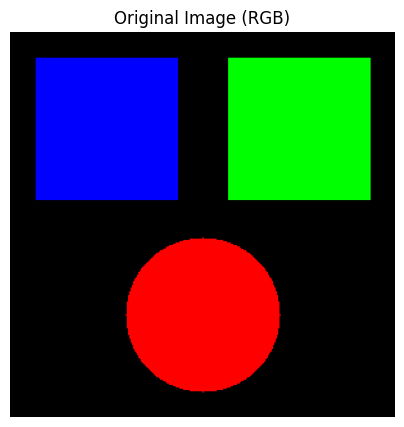

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a synthetic RGB/BGR image for demonstration
# It will have red, green, and blue blocks
img_size = 300
img = np.zeros((img_size, img_size, 3), dtype=np.uint8)

# Draw some colorful shapes
cv2.rectangle(img, (20, 20), (130, 130), (255, 0, 0), -1)      # Blue block (in BGR)
cv2.rectangle(img, (170, 20), (280, 130), (0, 255, 0), -1)    # Green block (in BGR)
cv2.circle(img, (150, 220), 60, (0, 0, 255), -1)              # Red circle (in BGR)

# OpenCV loads/creates images in BGR format.
# To display correctly with Matplotlib, we convert BGR to RGB.
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.title('Original Image (RGB)')
plt.axis('off')
plt.show()

### 1. Color Space Conversion
We convert our BGR image to:
- **Grayscale**: Essential for many image processing pipelines like edge detection.
- **HSV (Hue, Saturation, Value)**: Highly useful for color-based segmentation and thresholding.

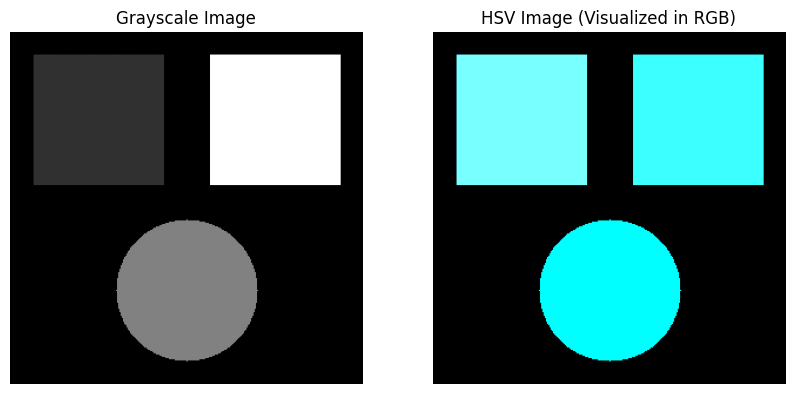

In [2]:
# BGR to Grayscale
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# BGR to HSV
hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Plot the converted images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(gray_img, cmap='gray')
axes[0].set_title('Grayscale Image')
axes[0].axis('off')

# HSV is usually displayed as-is for visualization, though its channels look unusual in RGB mapping
axes[1].imshow(hsv_img)
axes[1].set_title('HSV Image (Visualized in RGB)')
axes[1].axis('off')

plt.show()

### 2. Basic Thresholding
Thresholding creates binary images (black and white) based on pixel intensity. Here, we apply **Binary Thresholding** and **Inverse Binary Thresholding** to the Grayscale image.

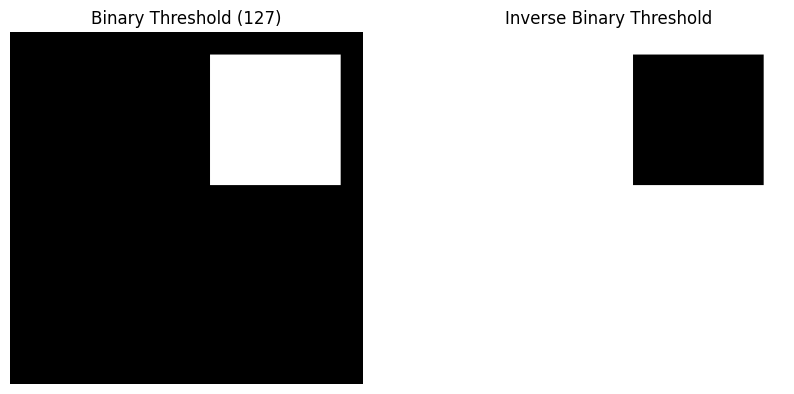

In [3]:
# Apply Simple Thresholding
# Any pixel value above 127 will be set to 255 (white), others to 0 (black)
_, thresh_binary = cv2.threshold(gray_img, 127, 255, cv2.THRESH_BINARY)

# Apply Inverse Thresholding
# Any pixel value above 127 will be set to 0, others to 255
_, thresh_binary_inv = cv2.threshold(gray_img, 127, 255, cv2.THRESH_BINARY_INV)

# Display Thresholding Results
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(thresh_binary, cmap='gray')
axes[0].set_title('Binary Threshold (127)')
axes[0].axis('off')

axes[1].imshow(thresh_binary_inv, cmap='gray')
axes[1].set_title('Inverse Binary Threshold')
axes[1].axis('off')

plt.show()

### 3. Finding and Drawing Contours
Contours are curves joining all the continuous points along a boundary that have the same color or intensity. We typically find contours on a binary image (like our `thresh_binary` output).

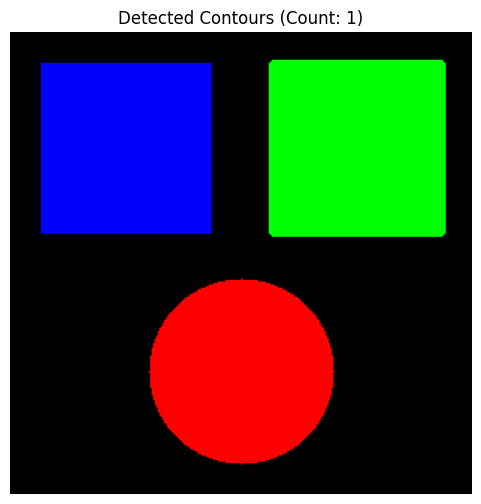

In [4]:
# Find contours in the binary image
# cv2.RETR_EXTERNAL: retrieves only the outermost contours
# cv2.CHAIN_APPROX_SIMPLE: compresses horizontal, diagonal, and vertical segments and leaves only their end points
contours, hierarchy = cv2.findContours(thresh_binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Create a copy of the original image to draw contours on
img_contours = img_rgb.copy()

# Draw all detected contours
# -1 specifies drawing all contours; (0, 255, 0) is the color (green); 3 is the thickness
cv2.drawContours(img_contours, contours, -1, (0, 255, 0), 3)

# Display the results
plt.figure(figsize=(6, 6))
plt.imshow(img_contours)
plt.title(f'Detected Contours (Count: {len(contours)})')
plt.axis('off')
plt.show()